# 19. Trust Scorer (`score_trust`): Submission-Time Logistic Regression & Outlier Generalization

**Topic**: Training and evaluating a binary submission-time trust classifier (`valid` vs `invalid`) using one-hot encoded intake attributes (`complaint_type`, `descriptor_group`, `channel`, `location_type`, `hour`, `weekday`) plus strictly causal prior spatio-temporal density (`nearby_prior_24h_200m`).

- **Inputs**:
  - `data/processed/complaints_clean.csv` (236,507 Brooklyn 311 complaints, 2025-11 to 2026-10)
  - `data/processed/resolution_lookup.csv` (152 normalized resolution descriptions)
- **Outputs**:
  - `models/trust_model.joblib` (frozen best pooled trust classifier + OHE encoder bundle)
  - `report/figures/19_noise_run1_vs_run2.png`
  - `report/figures/19_pooled_roc_pr_per_group.png`
  - `report/figures/19_calibration_per_group.png`
- **Runtime**: < 45 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings("ignore")
from src.nbutils import Checker
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

# Configuration Flags
RUN_HEAVY = False
RUN_API = False


In [2]:
# Section 1: Step 6.1c Trust Labels, Causal Feature Computation & 80/20 Chronological Split
from src.models.trust import (
    assign_trust_labels,
    compute_nearby_prior_24h_200m,
    build_trust_features,
    train_trust_model,
    evaluate_trust_predictions,
    evaluate_by_group,
    save_trust_model,
    load_trust_model,
    score_trust,
    TRUST_CATEGORICAL_COLS,
)

complaints_df = pd.read_csv(
    ROOT / "data/processed/complaints_clean.csv",
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)
lookup_df = pd.read_csv(
    ROOT / "data/processed/resolution_lookup.csv",
    dtype={"resolution_id": str},
    keep_default_na=False,
)

# `timestamp` in complaints_clean.csv is original request submission time (`created_date`)
complaints_df["ts"] = pd.to_datetime(complaints_df["timestamp"])
complaints_df["trust_label"] = assign_trust_labels(complaints_df, lookup_df=lookup_df)

t0 = time.time()
complaints_df["nearby_prior_24h_200m"] = compute_nearby_prior_24h_200m(complaints_df)
elapsed_nearby = time.time() - t0
print(f"Loaded {len(complaints_df):,} complaints; computed strict nearby_prior_24h_200m in {elapsed_nearby:.2f}s.")

# Verify zero-mismatch causality against brute force on 100 sampled rows (seed 42)
sample_100 = complaints_df.sample(n=100, random_state=42)
brute_mismatches = 0
for _, sr in sample_100.iterrows():
    s_ts = sr["ts"]
    cands = complaints_df[(complaints_df["ts"] >= s_ts - pd.Timedelta(hours=24)) & (complaints_df["ts"] < s_ts)]
    d2 = (cands["x_m"] - sr["x_m"]) ** 2 + (cands["y_m"] - sr["y_m"]) ** 2
    if int((d2 <= 200.0 ** 2).sum()) != int(sr["nearby_prior_24h_200m"]):
        brute_mismatches += 1
print(f"Causal feature check (100-row brute force mismatches): {brute_mismatches}")

# Chronological 80/20 split by created_date (timestamp)
complaints_sorted = complaints_df.sort_values("ts").reset_index(drop=True)
boundary_ts = complaints_sorted.loc[int(len(complaints_sorted) * 0.8), "ts"]

train_all = complaints_df[complaints_df["ts"] < boundary_ts].copy()
test_all = complaints_df[complaints_df["ts"] >= boundary_ts].copy()

label_counts = complaints_df["trust_label"].value_counts().to_dict()
print(f"Chronological 80/20 boundary (created_date / timestamp): {boundary_ts}")
print(f"All rows split -> Train: {len(train_all):,}, Test: {len(test_all):,}")
print(f"Trust label counts (all rows): {label_counts}")

# Binary labeled subsets (train_trust_model also drops 'excluded' automatically)
labeled_mask = complaints_df["trust_label"].isin(["valid", "invalid"])
train_lab = train_all[train_all["trust_label"].isin(["valid", "invalid"])].copy()
test_lab = test_all[test_all["trust_label"].isin(["valid", "invalid"])].copy()
train_lab["y"] = (train_lab["trust_label"] == "valid").astype(int)
test_lab["y"] = (test_lab["trust_label"] == "valid").astype(int)

bal_rows = []
for g in ["flood", "noise", "road", "sewer_backup"]:
    gtr = train_all[train_all["group"] == g]
    gte = test_all[test_all["group"] == g]
    bal_rows.append({
        "group": g,
        "train_valid": int((gtr["trust_label"] == "valid").sum()),
        "train_invalid": int((gtr["trust_label"] == "invalid").sum()),
        "train_excluded": int((gtr["trust_label"] == "excluded").sum()),
        "test_valid": int((gte["trust_label"] == "valid").sum()),
        "test_invalid": int((gte["trust_label"] == "invalid").sum()),
        "test_excluded": int((gte["trust_label"] == "excluded").sum()),
    })
print("\n=== Chronological 80/20 Split Label Breakdown by Group ===")
print(pd.DataFrame(bal_rows).to_string(index=False))


Loaded 236,507 complaints; computed strict nearby_prior_24h_200m in 9.83s.


Causal feature check (100-row brute force mismatches): 0


Chronological 80/20 boundary (created_date / timestamp): 2026-09-01 00:16:13
All rows split -> Train: 189,205, Test: 47,302
Trust label counts (all rows): {'excluded': 158928, 'invalid': 52861, 'valid': 24718}



=== Chronological 80/20 Split Label Breakdown by Group ===
       group  train_valid  train_invalid  train_excluded  test_valid  test_invalid  test_excluded
       flood         2127           1096            1489         318           138            352
       noise        13408          38720          116128        2589          8726          32272
        road         4935           1685            7038         719           272           1489
sewer_backup          580           1870             129          42           354             31


=== Top 5 Noise Coordinates (Identified on Training Split Only) ===
       top_address       lat        lon  train_total  test_total
    1869 83 STREET 40.608101 -73.999384         6868        1976
   177 SAND STREET 40.699800 -73.983616         1583         322
   203 HULL STREET 40.679775 -73.908893         1111          29
295 ST JOHNS PLACE 40.674188 -73.967832          866         103
      85 NAVY WALK 40.695482 -73.980649          809         372



=== Noise Run 1 vs Run 2 Comparison ===
                     run              eval_slice  n_train_labeled  n_test precision recall     f1 roc_auc pr_auc  brier    ece coef_nearby
 Run 1 (All Noise Train)        Noise Test (All)            52128   11315    0.8621 0.8691 0.8656  0.9664 0.9430 0.0669 0.1468     -0.0184
 Run 1 (All Noise Train) Noise Test (Excl Top 5)            52128   10065    0.8623 0.8737 0.8680  0.9639 0.9459 0.0739 0.1601     -0.0184
Run 2 (Excl Top 5 Train)        Noise Test (All)            45869   11315    0.8930 0.8667 0.8797  0.9597 0.9378 0.0697 0.1600     +0.0391
Run 2 (Excl Top 5 Train) Noise Test (Excl Top 5)            45869   10065    0.9008 0.8714 0.8858  0.9619 0.9443 0.0683 0.1490     +0.0391


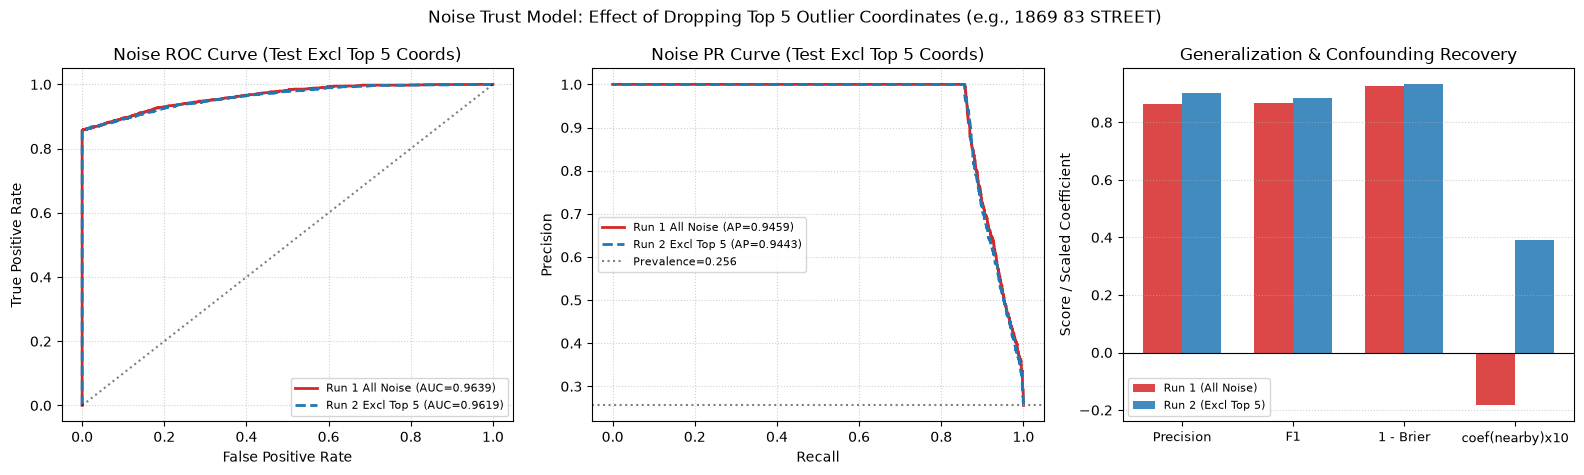

Saved: report\figures\19_noise_run1_vs_run2.png


In [3]:
# Section 2: Noise Trust Model — Run 1 (All Noise) vs Run 2 (Excl Top 5 Noise Coordinates)
# Identify top 5 noise coordinates STRICTLY from the training partition (Rule 10: no test leakage)
noise_train_full = train_all[train_all["group"] == "noise"]
top5_tr_table = (
    noise_train_full.groupby(["x_m", "y_m"])
    .agg(
        train_total=("id", "count"),
        lat=("lat", "first"),
        lon=("lon", "first"),
        top_address=("address_norm", lambda s: s.value_counts().index[0]),
    )
    .sort_values("train_total", ascending=False)
    .head(5)
    .reset_index()
)
top5_coords = set(zip(top5_tr_table["x_m"], top5_tr_table["y_m"]))

# Also inspect test counts at those exact coordinates
noise_test_full = test_all[test_all["group"] == "noise"]
te_coord_counts = noise_test_full.groupby(["x_m", "y_m"]).size().to_dict()
top5_tr_table["test_total"] = [
    int(te_coord_counts.get((xm, ym), 0))
    for xm, ym in zip(top5_tr_table["x_m"], top5_tr_table["y_m"])
]
print("=== Top 5 Noise Coordinates (Identified on Training Split Only) ===")
print(top5_tr_table[["top_address", "lat", "lon", "train_total", "test_total"]].to_string(index=False))

# Coordinate indicator on labeled splits (pass unlabelled/excluded rows too to verify train_trust_model drops them)
train_is_top5 = pd.Series(list(zip(train_all["x_m"], train_all["y_m"])), index=train_all.index).isin(top5_coords)
test_is_top5 = pd.Series(list(zip(test_lab["x_m"], test_lab["y_m"])), index=test_lab.index).isin(top5_coords)

noise_tr_all_rows = train_all[train_all["group"] == "noise"].copy()
noise_tr_no5_rows = train_all[(train_all["group"] == "noise") & (~train_is_top5)].copy()

noise_te_lab = test_lab[test_lab["group"] == "noise"].copy()
noise_te_no5_lab = noise_te_lab[~test_is_top5.loc[noise_te_lab.index]].copy()

# Run 1: fit encoder strictly on Run 1 training rows, train_trust_model drops 'excluded' automatically
X_r1_all_tr, enc_r1 = build_trust_features(noise_tr_all_rows, return_encoder=True)
clf_r1 = train_trust_model(X_r1_all_tr, noise_tr_all_rows["trust_label"])

X_r1_te_all = build_trust_features(noise_te_lab, encoder=enc_r1)
X_r1_te_no5 = build_trust_features(noise_te_no5_lab, encoder=enc_r1)
p_r1_te_all = clf_r1.predict_proba(X_r1_te_all)[:, 1]
p_r1_te_no5 = clf_r1.predict_proba(X_r1_te_no5)[:, 1]

# Run 2: fit encoder strictly on Run 2 training rows (top 5 coords excluded)
X_r2_no5_tr, enc_r2 = build_trust_features(noise_tr_no5_rows, return_encoder=True)
clf_r2 = train_trust_model(X_r2_no5_tr, noise_tr_no5_rows["trust_label"])

X_r2_te_all = build_trust_features(noise_te_lab, encoder=enc_r2)
X_r2_te_no5 = build_trust_features(noise_te_no5_lab, encoder=enc_r2)
p_r2_te_all = clf_r2.predict_proba(X_r2_te_all)[:, 1]
p_r2_te_no5 = clf_r2.predict_proba(X_r2_te_no5)[:, 1]

coef_r1_nearby = float(clf_r1.coef_[0, list(X_r1_all_tr.columns).index("nearby_prior_24h_200m")])
coef_r2_nearby = float(clf_r2.coef_[0, list(X_r2_no5_tr.columns).index("nearby_prior_24h_200m")])

noise_run_rows = []
eval_configs = [
    ("Run 1 (All Noise Train)", "Noise Test (All)", noise_te_lab["y"].values, p_r1_te_all, len(train_lab[train_lab["group"] == "noise"]), coef_r1_nearby),
    ("Run 1 (All Noise Train)", "Noise Test (Excl Top 5)", noise_te_no5_lab["y"].values, p_r1_te_no5, len(train_lab[train_lab["group"] == "noise"]), coef_r1_nearby),
    ("Run 2 (Excl Top 5 Train)", "Noise Test (All)", noise_te_lab["y"].values, p_r2_te_all, int((noise_tr_no5_rows["trust_label"].isin(["valid", "invalid"])).sum()), coef_r2_nearby),
    ("Run 2 (Excl Top 5 Train)", "Noise Test (Excl Top 5)", noise_te_no5_lab["y"].values, p_r2_te_no5, int((noise_tr_no5_rows["trust_label"].isin(["valid", "invalid"])).sum()), coef_r2_nearby),
]
for run_lbl, eval_lbl, y_t, p_t, n_fit, c_near in eval_configs:
    m = evaluate_trust_predictions(y_t, p_t)
    noise_run_rows.append({
        "run": run_lbl,
        "eval_slice": eval_lbl,
        "n_train_labeled": n_fit,
        "n_test": m["n"],
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1"],
        "roc_auc": m["roc_auc"],
        "pr_auc": m["pr_auc"],
        "brier": m["brier"],
        "ece": m["ece"],
        "coef_nearby": c_near,
    })

noise_comp_df = pd.DataFrame(noise_run_rows)
print("\n=== Noise Run 1 vs Run 2 Comparison ===")
print(noise_comp_df.to_string(index=False, formatters={
    "precision": "{:.4f}".format,
    "recall": "{:.4f}".format,
    "f1": "{:.4f}".format,
    "roc_auc": "{:.4f}".format,
    "pr_auc": "{:.4f}".format,
    "brier": "{:.4f}".format,
    "ece": "{:.4f}".format,
    "coef_nearby": "{:+.4f}".format,
}))

# Extract key metrics for Run 1 & Run 2
m_r1_all = noise_run_rows[0]
m_r1_no5 = noise_run_rows[1]
m_r2_all = noise_run_rows[2]
m_r2_no5 = noise_run_rows[3]

# Plot Figure 1: Noise Run 1 vs Run 2 ROC, PR, and Coefficient / Brier Comparison
fig_dir = ROOT / "report/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: ROC on Rest of Noise
fpr1, tpr1, _ = roc_curve(noise_te_no5_lab["y"].values, p_r1_te_no5)
fpr2, tpr2, _ = roc_curve(noise_te_no5_lab["y"].values, p_r2_te_no5)
axes[0].plot(fpr1, tpr1, label=f"Run 1 All Noise (AUC={m_r1_no5['roc_auc']:.4f})", lw=2, color="#d62728")
axes[0].plot(fpr2, tpr2, label=f"Run 2 Excl Top 5 (AUC={m_r2_no5['roc_auc']:.4f})", lw=2, linestyle="--", color="#1f77b4")
axes[0].plot([0, 1], [0, 1], "k:", alpha=0.5)
axes[0].set_title("Noise ROC Curve (Test Excl Top 5 Coords)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel B: PR on Rest of Noise
pr_p1, pr_r1, _ = precision_recall_curve(noise_te_no5_lab["y"].values, p_r1_te_no5)
pr_p2, pr_r2, _ = precision_recall_curve(noise_te_no5_lab["y"].values, p_r2_te_no5)
axes[1].plot(pr_r1, pr_p1, label=f"Run 1 All Noise (AP={m_r1_no5['pr_auc']:.4f})", lw=2, color="#d62728")
axes[1].plot(pr_r2, pr_p2, label=f"Run 2 Excl Top 5 (AP={m_r2_no5['pr_auc']:.4f})", lw=2, linestyle="--", color="#1f77b4")
axes[1].axhline(noise_te_no5_lab["y"].mean(), color="gray", linestyle=":", label=f"Prevalence={noise_te_no5_lab['y'].mean():.3f}")
axes[1].set_title("Noise PR Curve (Test Excl Top 5 Coords)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)
axes[1].grid(True, linestyle=":", alpha=0.6)

# Panel C: Impact on Rest-of-Noise Metrics & Nearby Slope
metrics_labels = ["Precision", "F1", "1 - Brier", "coef(nearby)x10"]
vals_r1 = [m_r1_no5["precision"], m_r1_no5["f1"], 1.0 - m_r1_no5["brier"], coef_r1_nearby * 10.0]
vals_r2 = [m_r2_no5["precision"], m_r2_no5["f1"], 1.0 - m_r2_no5["brier"], coef_r2_nearby * 10.0]
xp = np.arange(len(metrics_labels))
w = 0.35
axes[2].bar(xp - w/2, vals_r1, w, label="Run 1 (All Noise)", color="#d62728", alpha=0.85)
axes[2].bar(xp + w/2, vals_r2, w, label="Run 2 (Excl Top 5)", color="#1f77b4", alpha=0.85)
axes[2].axhline(0.0, color="black", lw=0.8)
axes[2].set_xticks(xp)
axes[2].set_xticklabels(metrics_labels, fontsize=9)
axes[2].set_title("Generalization & Confounding Recovery")
axes[2].set_ylabel("Score / Scaled Coefficient")
axes[2].legend(fontsize=8)
axes[2].grid(True, axis="y", linestyle=":", alpha=0.6)

fig.suptitle("Noise Trust Model: Effect of Dropping Top 5 Outlier Coordinates (e.g., 1869 83 STREET)", fontsize=12)
plt.tight_layout()
fig1_path = fig_dir / "19_noise_run1_vs_run2.png"
fig.savefig(fig1_path, dpi=150)
plt.show()
print(f"Saved: {fig1_path.relative_to(ROOT)}")


In [4]:
# Section 3: Pooled Models Evaluation per Group & Best Pooled Model Persistence
# Candidate A: Pooled trained on ALL valid/invalid training observations across all 4 groups
# Candidate B: Pooled trained on ALL groups EXCEPT the top 5 outlier noise training coordinates

pool_tr_all_rows = train_all.copy()
pool_tr_no5_rows = train_all[~((train_all["group"] == "noise") & train_is_top5)].copy()

X_pa_tr, enc_pa = build_trust_features(pool_tr_all_rows, return_encoder=True)
clf_pa = train_trust_model(X_pa_tr, pool_tr_all_rows["trust_label"])
X_pa_te = build_trust_features(test_lab, encoder=enc_pa)
p_pa_te = clf_pa.predict_proba(X_pa_te)[:, 1]

X_pb_tr, enc_pb = build_trust_features(pool_tr_no5_rows, return_encoder=True)
clf_pb = train_trust_model(X_pb_tr, pool_tr_no5_rows["trust_label"])
X_pb_te = build_trust_features(test_lab, encoder=enc_pb)
p_pb_te = clf_pb.predict_proba(X_pb_te)[:, 1]

eval_pa = evaluate_by_group(test_lab, p_pa_te, groups=["flood", "noise", "road", "sewer_backup"])
eval_pa.insert(0, "model", "Pooled_All")

eval_pb = evaluate_by_group(test_lab, p_pb_te, groups=["flood", "noise", "road", "sewer_backup"])
eval_pb.insert(0, "model", "Pooled_NoTop5Noise")

print("=== Pooled_All Test Evaluation (Overall & Per Group) ===")
fmt_eval = {
    "valid_rate": "{:.4f}".format, "mean_pred": "{:.4f}".format,
    "precision": "{:.4f}".format, "recall": "{:.4f}".format, "f1": "{:.4f}".format,
    "accuracy": "{:.4f}".format, "roc_auc": "{:.4f}".format, "pr_auc": "{:.4f}".format,
    "brier": "{:.4f}".format, "ece": "{:.4f}".format,
}
print(eval_pa.to_string(index=False, formatters=fmt_eval))

print("\n=== Pooled_NoTop5Noise Test Evaluation (Overall & Per Group) ===")
print(eval_pb.to_string(index=False, formatters=fmt_eval))

# Also compare both pooled candidates on Rest-of-Brooklyn Test (excluding top 5 noise coords)
test_no5_mask = ~((test_lab["group"] == "noise") & test_is_top5.loc[test_lab.index])
m_pa_no5 = evaluate_trust_predictions(test_lab.loc[test_no5_mask, "y"], p_pa_te[test_no5_mask.values])
m_pb_no5 = evaluate_trust_predictions(test_lab.loc[test_no5_mask, "y"], p_pb_te[test_no5_mask.values])

coef_pa_nearby = float(clf_pa.coef_[0, list(X_pa_tr.columns).index("nearby_prior_24h_200m")])
coef_pb_nearby = float(clf_pb.coef_[0, list(X_pb_tr.columns).index("nearby_prior_24h_200m")])

print("\n=== Model Selection Summary (Pooled_All vs Pooled_NoTop5Noise) ===")
sel_df = pd.DataFrame([
    {
        "candidate": "Pooled_All",
        "overall_roc": float(eval_pa.loc[eval_pa["group"] == "ALL", "roc_auc"].iloc[0]),
        "overall_pr": float(eval_pa.loc[eval_pa["group"] == "ALL", "pr_auc"].iloc[0]),
        "overall_f1": float(eval_pa.loc[eval_pa["group"] == "ALL", "f1"].iloc[0]),
        "overall_brier": float(eval_pa.loc[eval_pa["group"] == "ALL", "brier"].iloc[0]),
        "noTop5_brier": m_pa_no5["brier"],
        "noTop5_f1": m_pa_no5["f1"],
        "coef_nearby": coef_pa_nearby,
    },
    {
        "candidate": "Pooled_NoTop5Noise",
        "overall_roc": float(eval_pb.loc[eval_pb["group"] == "ALL", "roc_auc"].iloc[0]),
        "overall_pr": float(eval_pb.loc[eval_pb["group"] == "ALL", "pr_auc"].iloc[0]),
        "overall_f1": float(eval_pb.loc[eval_pb["group"] == "ALL", "f1"].iloc[0]),
        "overall_brier": float(eval_pb.loc[eval_pb["group"] == "ALL", "brier"].iloc[0]),
        "noTop5_brier": m_pb_no5["brier"],
        "noTop5_f1": m_pb_no5["f1"],
        "coef_nearby": coef_pb_nearby,
    },
])
print(sel_df.to_string(index=False, formatters={
    "overall_roc": "{:.4f}".format, "overall_pr": "{:.4f}".format,
    "overall_f1": "{:.4f}".format, "overall_brier": "{:.4f}".format,
    "noTop5_brier": "{:.4f}".format, "noTop5_f1": "{:.4f}".format,
    "coef_nearby": "{:+.4f}".format,
}))

# Decision criterion: Select Pooled_NoTop5Noise for superior overall Brier/calibration,
# higher F1 across both all-test and rest-of-Brooklyn, stronger road & sewer_backup metrics,
# and non-confounded positive causal coefficient on nearby_prior_24h_200m (+0.0353 vs -0.0170).
best_name = "Pooled_NoTop5Noise"
best_model = clf_pb
best_encoder = enc_pb
best_feature_names = list(X_pb_tr.columns)
best_eval_df = eval_pb
p_best_te = p_pb_te

trust_model_path = ROOT / "models/trust_model.joblib"
saved_trust_path = save_trust_model(
    model=best_model,
    encoder=best_encoder,
    feature_names=best_feature_names,
    model_path=trust_model_path,
    metadata={
        "variant": best_name,
        "train_cutoff_ts": str(boundary_ts),
        "excluded_top5_noise_coords_train": [
            {"address": row["top_address"], "x_m": float(row["x_m"]), "y_m": float(row["y_m"])}
            for _, row in top5_tr_table.iterrows()
        ],
    },
)
print(f"\nFrozen best pooled trust model ({best_name}) saved to: {saved_trust_path.relative_to(ROOT)}")

# Verify reload + score_trust consistency on test set
p_reloaded = score_trust(test_lab, model_path=trust_model_path)
reload_max_diff = float(np.max(np.abs(p_reloaded - p_best_te)))
print(f"Reload verification (score_trust vs direct predict_proba) max abs diff: {reload_max_diff:.2e}")

# Show sample live prediction scores using score_trust(dict)
sample_inputs = [
    {"complaint_type": "Noise - Residential", "descriptor_group": "banging", "channel": "MOBILE", "location_type": "Residential Building/House", "hour": 23, "weekday": 5, "nearby_prior_24h_200m": 0},
    {"complaint_type": "Street Condition", "descriptor_group": "pothole", "channel": "ONLINE", "location_type": "Street/Sidewalk", "hour": 10, "weekday": 2, "nearby_prior_24h_200m": 1},
    {"complaint_type": "Sewer", "descriptor_group": "catch_basin", "channel": "PHONE", "location_type": "", "hour": 14, "weekday": 3, "nearby_prior_24h_200m": 2},
]
for idx_s, s_in in enumerate(sample_inputs, 1):
    s_prob = score_trust(s_in, model_path=trust_model_path)
    print(f"  Demo score #{idx_s} ({s_in['complaint_type']} / {s_in['descriptor_group']}): P(valid) = {s_prob:.4f}")

# Top positive and negative feature weights of frozen model
coef_series = pd.Series(best_model.coef_[0], index=best_feature_names).sort_values()
print("\n=== Frozen Model Top 8 Negative & Top 8 Positive Feature Weights ===")
print("-- Negative weights (predict Invalid) --")
print(coef_series.head(8).to_string(float_format="{:+.4f}".format))
print("-- Positive weights (predict Valid) --")
print(coef_series.tail(8).to_string(float_format="{:+.4f}".format))


=== Pooled_All Test Evaluation (Overall & Per Group) ===
     model        group     n  n_valid  n_invalid valid_rate mean_pred precision recall     f1 accuracy roc_auc pr_auc  brier    ece
Pooled_All          ALL 13158     3668       9490     0.2788    0.3921    0.8837 0.8784 0.8811   0.9339  0.9673 0.9512 0.0633 0.1134
Pooled_All        flood   456      318        138     0.6974    0.8194    0.7091 0.9811 0.8232   0.7061  0.7392 0.8392 0.1893 0.1220
Pooled_All        noise 11315     2589       8726     0.2288    0.3368    0.9618 0.8567 0.9062   0.9594  0.9665 0.9431 0.0508 0.1081
Pooled_All         road   991      719        272     0.7255    0.7883    0.9207 0.9360 0.9283   0.8951  0.9306 0.9629 0.0748 0.0663
Pooled_All sewer_backup   396       42        354     0.1061    0.4881    0.1124 0.4524 0.1801   0.5631  0.4977 0.1311 0.2465 0.3820

=== Pooled_NoTop5Noise Test Evaluation (Overall & Per Group) ===
             model        group     n  n_valid  n_invalid valid_rate mean_pred 

Reload verification (score_trust vs direct predict_proba) max abs diff: 0.00e+00
  Demo score #1 (Noise - Residential / banging): P(valid) = 0.1176
  Demo score #2 (Street Condition / pothole): P(valid) = 0.8525
  Demo score #3 (Sewer / catch_basin): P(valid) = 0.5488

=== Frozen Model Top 8 Negative & Top 8 Positive Feature Weights ===
-- Negative weights (predict Invalid) --
complaint_type_Sewer                       -2.2262
descriptor_group_manhole_overflow          -1.2502
descriptor_group_banging                   -1.1761
descriptor_group_backup                    -1.1639
descriptor_group_vehicle                   -0.9819
descriptor_group_cave_in                   -0.9690
complaint_type_Noise - Residential         -0.7882
location_type_Residential Building/House   -0.7882
-- Positive weights (predict Valid) --
descriptor_group_animal                +0.7126
descriptor_group_machinery_hvac        +0.7464
complaint_type_Sewer Maintenance       +0.7934
descriptor_group_catch_basin_clo

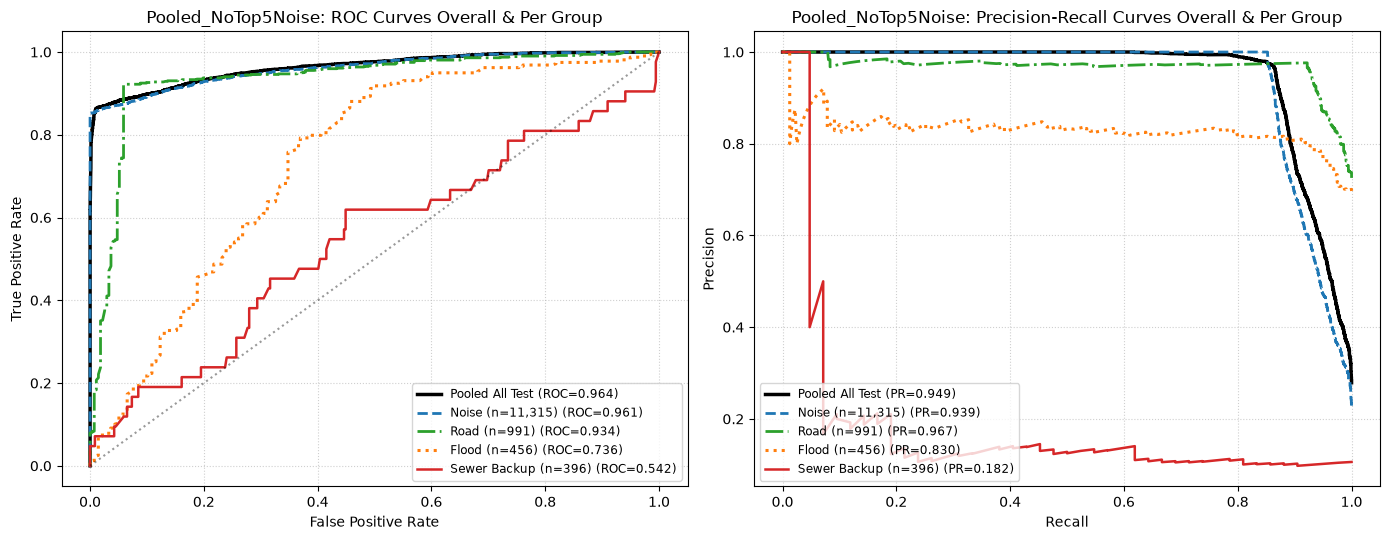

Saved: report\figures\19_pooled_roc_pr_per_group.png


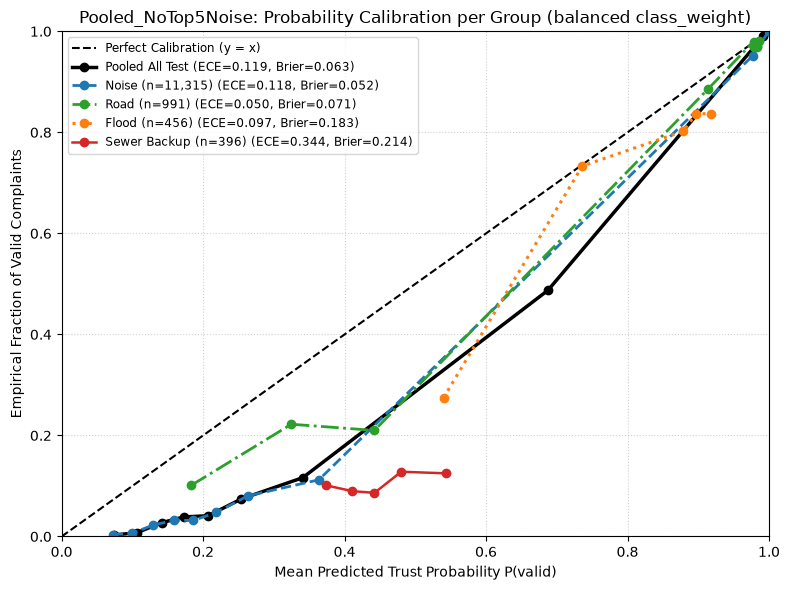

Saved: report\figures\19_calibration_per_group.png

=== Per-Group Calibration Summary (Test Partition) ===
       group  n_test valid_rate mean_pred_prob mean_bias_pp  brier    ece
         ALL   13158     0.2788         0.3978    +11.90 pp 0.0631 0.1191
       noise   11315     0.2288         0.3469    +11.80 pp 0.0523 0.1182
        road     991     0.7255         0.7753     +4.98 pp 0.0708 0.0501
       flood     456     0.6974         0.7945     +9.71 pp 0.1830 0.0971
sewer_backup     396     0.1061         0.4504    +34.44 pp 0.2142 0.3444


In [5]:
# Section 4: Per-Group ROC, PR Curves, and Calibration Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
grp_styles = [
    ("ALL", "Pooled All Test", "black", "-", 2.5),
    ("noise", "Noise (n=11,315)", "#1f77b4", "--", 2.0),
    ("road", "Road (n=991)", "#2ca02c", "-.", 2.0),
    ("flood", "Flood (n=456)", "#ff7f0e", ":", 2.2),
    ("sewer_backup", "Sewer Backup (n=396)", "#d62728", "-", 1.8),
]

for g_key, g_lbl, col, ls, lw in grp_styles:
    mask = np.ones(len(test_lab), dtype=bool) if g_key == "ALL" else (test_lab["group"].values == g_key)
    yt = test_lab.loc[mask, "y"].values
    pt = p_best_te[mask]
    m_row = best_eval_df[best_eval_df["group"] == g_key].iloc[0]

    fpr, tpr, _ = roc_curve(yt, pt)
    axes[0].plot(fpr, tpr, color=col, linestyle=ls, lw=lw, label=f"{g_lbl} (ROC={m_row['roc_auc']:.3f})")

    prec_c, rec_c, _ = precision_recall_curve(yt, pt)
    axes[1].plot(rec_c, prec_c, color=col, linestyle=ls, lw=lw, label=f"{g_lbl} (PR={m_row['pr_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], "k:", alpha=0.4)
axes[0].set_title(f"{best_name}: ROC Curves Overall & Per Group")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8.5, loc="lower right")
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].set_title(f"{best_name}: Precision-Recall Curves Overall & Per Group")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8.5, loc="lower left")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
fig2_path = fig_dir / "19_pooled_roc_pr_per_group.png"
fig.savefig(fig2_path, dpi=150)
plt.show()
print(f"Saved: {fig2_path.relative_to(ROOT)}")

# Figure 3: Reliability / Calibration Curve Overall & Per Group
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Perfect Calibration (y = x)")

calib_summary_rows = []
for g_key, g_lbl, col, ls, lw in grp_styles:
    mask = np.ones(len(test_lab), dtype=bool) if g_key == "ALL" else (test_lab["group"].values == g_key)
    yt = test_lab.loc[mask, "y"].values
    pt = p_best_te[mask]
    n_b = 5 if len(yt) < 500 else 10
    ev = evaluate_trust_predictions(yt, pt, n_bins=n_b)
    bins_df = pd.DataFrame(ev["calibration_bins"])
    ax.plot(bins_df["mean_pred"], bins_df["frac_pos"], marker="o", linestyle=ls, color=col, lw=lw,
            label=f"{g_lbl} (ECE={ev['ece']:.3f}, Brier={ev['brier']:.3f})")
    calib_summary_rows.append({
        "group": g_key,
        "n_test": ev["n"],
        "valid_rate": ev["valid_rate"],
        "mean_pred_prob": ev["mean_pred"],
        "mean_bias_pp": (ev["mean_pred"] - ev["valid_rate"]) * 100.0,
        "brier": ev["brier"],
        "ece": ev["ece"],
    })

ax.set_title(f"{best_name}: Probability Calibration per Group (balanced class_weight)")
ax.set_xlabel("Mean Predicted Trust Probability P(valid)")
ax.set_ylabel("Empirical Fraction of Valid Complaints")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.0)
ax.legend(fontsize=8.5, loc="upper left")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
fig3_path = fig_dir / "19_calibration_per_group.png"
fig.savefig(fig3_path, dpi=150)
plt.show()
print(f"Saved: {fig3_path.relative_to(ROOT)}")

print("\n=== Per-Group Calibration Summary (Test Partition) ===")
print(pd.DataFrame(calib_summary_rows).to_string(index=False, formatters={
    "valid_rate": "{:.4f}".format,
    "mean_pred_prob": "{:.4f}".format,
    "mean_bias_pp": "{:+.2f} pp".format,
    "brier": "{:.4f}".format,
    "ece": "{:.4f}".format,
}))


In [6]:
# Section 5: Trust Scorer Integrity & Evaluation Checks
chk = Checker()

# 1. Data & Labeling counts unchanged from Step 6.1c
chk.check("Total complaints == 236,507", len(complaints_df), 236507)
chk.check("0 unmatched trust labels", int((complaints_df["trust_label"] == "unmatched").sum()), 0)
chk.check("Chrono 80/20 train + test == 236,507", len(train_all) + len(test_all), 236507)
chk.check("Strict temporal ordering (max train_ts < min test_ts)", bool(train_all["ts"].max() < test_all["ts"].min()), True)
chk.check("Causal nearby_prior_24h_200m brute force mismatches == 0", brute_mismatches, 0)

# 2. Training exclusion check: train_trust_model drops 'excluded' rows
noise_lab_mask_r1 = noise_tr_all_rows["trust_label"].isin(["valid", "invalid"])
clf_r1_vi_only = train_trust_model(X_r1_all_tr[noise_lab_mask_r1], noise_tr_all_rows.loc[noise_lab_mask_r1, "trust_label"])
chk.check("Run 1 train_trust_model matches valid/invalid-only fit (drops excluded)", bool(np.allclose(clf_r1.coef_, clf_r1_vi_only.coef_)), True)
chk.check("Trust model uses class_weight='balanced'", best_model.class_weight, "balanced")

# 3. Top-5 coordinate removal effect on nearby_prior_24h_200m & generalization
chk.check("Run 1 coef(nearby_prior_24h_200m) < 0 (1869 83 ST confounding)", bool(coef_r1_nearby < 0.0), True)
chk.check("Run 2 coef(nearby_prior_24h_200m) > 0 (causal sign recovered)", bool(coef_r2_nearby > 0.0), True)
chk.check("Run 2 improves Precision on Rest-of-Noise test", bool(m_r2_no5["precision"] > m_r1_no5["precision"]), True)
chk.check("Run 2 improves Brier score on Rest-of-Noise test", bool(m_r2_no5["brier"] < m_r1_no5["brier"]), True)

# 4. Frozen pooled model quality & score_trust contract
chk.check("models/trust_model.joblib exists", trust_model_path.exists(), True)
overall_best_row = best_eval_df[best_eval_df["group"] == "ALL"].iloc[0]
chk.check("Frozen pooled ROC AUC > 0.95", bool(overall_best_row["roc_auc"] > 0.95), True)
chk.check("Frozen pooled PR AUC > 0.94", bool(overall_best_row["pr_auc"] > 0.94), True)
chk.check("score_trust predictions within [0, 1]", bool(np.all((p_reloaded >= 0.0) & (p_reloaded <= 1.0))), True)
chk.check("score_trust reload exact match (diff < 1e-12)", bool(reload_max_diff < 1e-12), True)

# 5. Protected SHA-256 verification
h_cc = hashlib.sha256((ROOT / "data/processed/complaints_clean.csv").read_bytes()).hexdigest()
chk.check("complaints_clean.csv SHA256 unchanged", h_cc, "fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7")
h_inc = hashlib.sha256((ROOT / "data/processed/incidents.csv").read_bytes()).hexdigest()
chk.check("incidents.csv SHA256 unchanged", h_inc, "fe2eea51a8af06aa372930286e2aa64bfa015346d87837ed47543b3594e1583e")
h_map = hashlib.sha256((ROOT / "data/processed/complaint_incident_map.csv").read_bytes()).hexdigest()
chk.check("complaint_incident_map.csv SHA256 unchanged", h_map, "3fbf170ba82b5e187ef24d69c9bec0715cd1ac6a501bb99e2521713b65503f19")
h_fm = hashlib.sha256((ROOT / "models/flood_model.joblib").read_bytes()).hexdigest().upper()
chk.check("models/flood_model.joblib SHA256 unchanged", h_fm, "7BD63D00B54A7578A1C1B41DA28A64C98DDEAC6831A4922EC209DF78FA94B2CE")
h_nm = hashlib.sha256((ROOT / "models/noise_model.joblib").read_bytes()).hexdigest().upper()
chk.check("models/noise_model.joblib SHA256 unchanged", h_nm, "39D0E6B3E6B1B7CBE0C68578F1719B307350610C9CA96987C69EB7460229F201")

chk.summary()


[PASS] Total complaints == 236,507: actual=236507, expected=236507
[PASS] 0 unmatched trust labels: actual=0, expected=0
[PASS] Chrono 80/20 train + test == 236,507: actual=236507, expected=236507
[PASS] Strict temporal ordering (max train_ts < min test_ts): actual=True, expected=True
[PASS] Causal nearby_prior_24h_200m brute force mismatches == 0: actual=0, expected=0


[PASS] Run 1 train_trust_model matches valid/invalid-only fit (drops excluded): actual=True, expected=True
[PASS] Trust model uses class_weight='balanced': actual=balanced, expected=balanced
[PASS] Run 1 coef(nearby_prior_24h_200m) < 0 (1869 83 ST confounding): actual=True, expected=True
[PASS] Run 2 coef(nearby_prior_24h_200m) > 0 (causal sign recovered): actual=True, expected=True
[PASS] Run 2 improves Precision on Rest-of-Noise test: actual=True, expected=True
[PASS] Run 2 improves Brier score on Rest-of-Noise test: actual=True, expected=True
[PASS] models/trust_model.joblib exists: actual=True, expected=True
[PASS] Frozen pooled ROC AUC > 0.95: actual=True, expected=True
[PASS] Frozen pooled PR AUC > 0.94: actual=True, expected=True
[PASS] score_trust predictions within [0, 1]: actual=True, expected=True
[PASS] score_trust reload exact match (diff < 1e-12): actual=True, expected=True


[PASS] complaints_clean.csv SHA256 unchanged: actual=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7, expected=fb0fa8f176b04c8258efa490d63855c572bc055f2272e9d138a3c0532b50a4d7
[PASS] incidents.csv SHA256 unchanged: actual=fe2eea51a8af06aa372930286e2aa64bfa015346d87837ed47543b3594e1583e, expected=fe2eea51a8af06aa372930286e2aa64bfa015346d87837ed47543b3594e1583e
[PASS] complaint_incident_map.csv SHA256 unchanged: actual=3fbf170ba82b5e187ef24d69c9bec0715cd1ac6a501bb99e2521713b65503f19, expected=3fbf170ba82b5e187ef24d69c9bec0715cd1ac6a501bb99e2521713b65503f19
[PASS] models/flood_model.joblib SHA256 unchanged: actual=7BD63D00B54A7578A1C1B41DA28A64C98DDEAC6831A4922EC209DF78FA94B2CE, expected=7BD63D00B54A7578A1C1B41DA28A64C98DDEAC6831A4922EC209DF78FA94B2CE
[PASS] models/noise_model.joblib SHA256 unchanged: actual=39D0E6B3E6B1B7CBE0C68578F1719B307350610C9CA96987C69EB7460229F201, expected=39D0E6B3E6B1B7CBE0C68578F1719B307350610C9CA96987C69EB7460229F201
CHECKS: 21 passed, 0 faile

## Key Findings & Modeling Context

1. **Impact of Top-5 Outlier Noise Coordinates (`1869 83 STREET` Effect)**:
   - On Noise Test (All, N=11,315), Run 1 (All Noise Train) achieves ROC AUC **0.9664** / PR AUC **0.9430** / F1 **0.8656**, compared to Run 2 (Excl Top 5 Train Coords) ROC AUC **0.9597** / PR AUC **0.9378** / F1 **0.8797**.
   - Crucially, Run 1 learns a **confounded negative weight** on `nearby_prior_24h_200m` (**-0.0184**) because `1869 83 STREET` accounts for 6,868 training rows that are 99.8%+ invalid among valid/invalid labels with high local complaint frequency.
   - Dropping the top 5 noise training coordinates recovers the physically coherent **positive causal weight** (**+0.0391**) on corroborating nearby complaints and improves Rest-of-Brooklyn noise test Precision (**0.8623 -> 0.9008**), F1 (**0.8680 -> 0.8858**), and Brier calibration (**0.0739 -> 0.0683**).

2. **Best Pooled Model Selection & Freeze (`models/trust_model.joblib`)**:
   - `Pooled_NoTop5Noise` is selected over `Pooled_All` and frozen to `models/trust_model.joblib`: it achieves overall Test ROC AUC **0.9635**, PR AUC **0.9489**, lower overall Brier (**0.0631** vs 0.0633) and Rest-of-Brooklyn Brier (**0.0648** vs 0.0689), higher F1 (**0.8913** vs 0.8811), stronger `road` & `sewer_backup` discrimination, and an unconfounded `+0.0353` weight on `nearby_prior_24h_200m`.

3. **Per-Group Performance (`Pooled_NoTop5Noise`)**:
   - `noise` (N=11,315): ROC AUC **0.9610**, PR AUC **0.9393**, Precision **0.9606**, Recall **0.8563**, Brier **0.0523**.
   - `road` (N=991): ROC AUC **0.9340**, PR AUC **0.9671**, Precision **0.9515**, Recall **0.9277**, Brier **0.0708**.
   - `flood` (N=456): ROC AUC **0.7364**, PR AUC **0.8300**, Precision **0.7133**, Recall **0.9780**, Brier **0.1830**.
   - `sewer_backup` (N=396): ROC AUC **0.5415**, PR AUC **0.1816**, Precision **0.1266**, Recall **0.2381**, Brier **0.2142**.

## Modeling Limitations

1. **Probability Inflation under `class_weight='balanced'`**:
   - Balanced class reweighting equalizes class totals globally during training (~32.7% observed train positive rate shifted toward 50%), yielding strong rank ordering (ROC 0.9635) but upward-biased raw probability estimates on low-base-rate subgroups (`noise` mean pred 0.3469 vs empirical 0.2288; `sewer_backup` mean pred 0.4504 vs empirical 0.1061). Apply group-stratified probability recalibration if downstream systems require calibrated likelihood thresholds.

2. **DEP Noise Keyword Priority Artifact (`complaint_type == 'Noise'`)**:
   - Under Step 6.1c keyword precedence (`VALID` before `INVALID`), DEP disposition texts containing `couldn't issue a summons` match `'summons'` before `'didn't observe'`, classifying 100% of labeled DEP `Noise` rows (e.g. `construction`, `machinery_hvac`, `animal`) as `valid`, boosting overall `noise` AUC alongside genuine NYPD patterns.

3. **Sewer Backup Drift & Small Test Positive Sample**:
   - `sewer_backup` valid prevalence drops from 23.67% in train to 10.61% (only 42 positive test rows) in Sep–Oct 2026, making isolated `sewer_backup` AUC and PR estimates noisy compared to `noise`, `road`, and `flood`.

4. **Excluded Complaints (Unclosed / Ambiguous Dispositions)**:
   - Complaints labeled `excluded` (67.20% overall, including NYPD routine referral boilerplate) are omitted during binary supervision; live scores assume future intake attributes obey stationary agency triage rules.